<a href="https://colab.research.google.com/github/vicente-gonzalez-ruiz/medical_imaging/blob/main/notebooks/unet_n2n.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Zero-Shot (Single Noisy Image) Self-Supervised Training
Here we implement a self-supervised strategy using ONLY a single noisy image (noisy_source). We will train the U-Net using a pixel-masking strategy: randomly masking out pixels in the input and calculating the loss only on those masked-out pixel locations compared to the original noisy pixels.


In [1]:
import urllib.request
from PIL import Image
import io
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

In [2]:
# Define the U-Net (see https://arxiv.org/pdf/1803.04189) (see https://github.com/sashrika15/noise2noise/blob/master/unet.py)

class Unet(nn.Module):
    '''
    Unet architecture for n2n.
    No batch norm, dropout
    '''

    def __init__(self, in_channels=3, out_channels=3):
            """Initializes U-Net."""

            super(Unet, self).__init__()

            self._block1 = nn.Sequential(
                nn.Conv2d(in_channels, 48, 3, stride=1, padding=1),
                nn.ReLU(inplace=True),
                nn.Conv2d(48, 48, 3, padding=1),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2))

            self._block2 = nn.Sequential(
                nn.Conv2d(48, 48, 3, stride=1, padding=1),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2))

            self._block3 = nn.Sequential(
                nn.Conv2d(48, 48, 3, stride=1, padding=1),
                nn.ReLU(inplace=True),
                nn.ConvTranspose2d(48, 48, 3, stride=2, padding=1, output_padding=1))

            self._block4 = nn.Sequential(
                nn.Conv2d(96, 96, 3, stride=1, padding=1),
                nn.ReLU(inplace=True),
                nn.Conv2d(96, 96, 3, stride=1, padding=1),
                nn.ReLU(inplace=True),
                nn.ConvTranspose2d(96, 96, 3, stride=2, padding=1, output_padding=1))

            self._block5 = nn.Sequential(
                nn.Conv2d(144, 96, 3, stride=1, padding=1),
                nn.ReLU(inplace=True),
                nn.Conv2d(96, 96, 3, stride=1, padding=1),
                nn.ReLU(inplace=True),
                nn.ConvTranspose2d(96, 96, 3, stride=2, padding=1, output_padding=1))

            self._block6 = nn.Sequential(
                nn.Conv2d(96 + in_channels, 64, 3, stride=1, padding=1),
                nn.ReLU(inplace=True),
                nn.Conv2d(64, 32, 3, stride=1, padding=1),
                nn.ReLU(inplace=True),
                nn.Conv2d(32, out_channels, 3, stride=1, padding=1),
                nn.LeakyReLU(0.1))


    def forward(self, x):

        #Encoder
        #print("X size = ", str(x.size()))
        pool1 = self._block1(x)
        #print(pool1.size())
        pool2 = self._block2(pool1)
        #print(pool2.size())
        pool3 = self._block2(pool2)
        #print(pool3.size())
        pool4 = self._block2(pool3)
        #print(pool4.size())
        pool5 = self._block2(pool4)
        #print(pool5.size())

        #Decoder
        upsample5 = self._block3(pool5)
        #print(upsample5.size())
        concat5 = torch.cat((upsample5, pool4), dim=1)
        #print(concat5.size())
        upsample4 = self._block4(concat5)
        #print(upsample4.size())
        concat4 = torch.cat((upsample4, pool3), dim=1)
        #print(concat4.size())
        upsample3 = self._block5(concat4)
        #print(upsample3.size())
        concat3 = torch.cat((upsample3, pool2), dim=1)
        #print(concat3.size())
        upsample2 = self._block5(concat3)
        #print(upsample2.size())
        concat2 = torch.cat((upsample2, pool1), dim=1)
        #print(concat2.size())
        upsample1 = self._block5(concat2)
        #print(upsample1.size())
        concat1 = torch.cat((upsample1, x), dim=1)
        #print(concat1.size())
        output = self._block6(concat1)
        #print(output.size())
        return output

    def summary(self):
        print('Unet summary: ')
        print(self._block1)
        print(self._block2)
        print(self._block3)
        print(self._block4)
        print(self._block5)
        print(self._block6)

Unet(in_channels=1, out_channels=1).summary()

Unet summary: 
Sequential(
  (0): Conv2d(1, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU(inplace=True)
  (2): Conv2d(48, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (3): ReLU(inplace=True)
  (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
)
Sequential(
  (0): Conv2d(48, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU(inplace=True)
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
)
Sequential(
  (0): Conv2d(48, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU(inplace=True)
  (2): ConvTranspose2d(48, 48, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
)
Sequential(
  (0): Conv2d(96, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU(inplace=True)
  (2): Conv2d(96, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (3): ReLU(inplace=True)
  (4): ConvTranspose2d(96, 96, kernel_size=(3, 3), stride=(2, 2), pad

In [3]:
# Determine the "device"

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cpu')

In [4]:
# Configure the denoiser's training

denoiser = Unet(in_channels=1, out_channels=1).to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(denoiser.parameters(), lr=0.001)
epochs = 10

In [5]:
# Load Lena

url = "https://www.hpca.ual.es/~vruiz/images/lena_512x512_gray.png"
with urllib.request.urlopen(url) as response:
    img_data = response.read()
    clean = Image.open(io.BytesIO(img_data)).convert('L')
clean = np.array(clean, dtype=np.uint8)

In [6]:
# Add noise

mean = 0
sigma = 25

# Ensure clean is treated as a numpy array for numpy-based noise creation
clean_np = clean.numpy() if isinstance(clean, torch.Tensor) else clean
gaussian_noise = np.random.normal(mean, sigma, clean_np.shape)
noisy = np.clip(clean_np + gaussian_noise, 0, 255).astype(np.uint8)

# Ensure clean_base is a PyTorch float tensor scaled to [0, 1]
clean_tensor = torch.from_numpy(clean_np) if isinstance(clean_np, np.ndarray) else clean
clean_base = clean_tensor.float() / 255.0

# Generate first independent noisy realization (noisy_source)
noise1 = torch.randn_like(clean_base) * (25.0 / 255.0)
noisy_source = torch.clamp(clean_base + noise1, 0.0, 1.0).unsqueeze(0).unsqueeze(0)

# Generate second independent noisy realization (noisy_target)
noise2 = torch.randn_like(clean_base) * (25.0 / 255.0)
noisy_target = torch.clamp(clean_base + noise2, 0.0, 1.0).unsqueeze(0).unsqueeze(0)

# 4. Create PyTorch Dataset and DataLoader
dataset = TensorDataset(noisy_source, noisy_target)
lena_loader = DataLoader(dataset, batch_size=1, shuffle=True)

# 5. Map the models and metrics to align with variables in the next cell's training loop
model_lena = denoiser
losses = []

# Prepare fixed noisy input scaled to [0, 1] for visual tracking
fixed_noisy_input = noisy_source.to(device)

In [18]:
img_size = 512
tile_size = 32

# Supervised Training (Noisy to Clean)

Here we implement a supervised denoising strategy. We use the original clean image to generate a collection of patch pairs: a noisy patch as input, and its corresponding clean patch as the target. The network is then trained using standard Mean Squared Error (MSE) loss with full supervision.

In [15]:
# Extract corresponding pairs of noisy and clean 32x32 patches
tiles_noisy_supervised = []
tiles_clean_supervised = []

for i in range(0, img_size, tile_size):
    for j in range(0, img_size, tile_size):
        # Slice out 32x32 patches from noisy_source and clean_base
        tile_noisy = noisy_source[:, :, i:i+tile_size, j:j+tile_size]
        tile_clean = clean_base.unsqueeze(0).unsqueeze(0)[:, :, i:i+tile_size, j:j+tile_size]

        tiles_noisy_supervised.append(tile_noisy)
        tiles_clean_supervised.append(tile_clean)

# Concatenate along the batch dimension
tiles_noisy_tensor = torch.cat(tiles_noisy_supervised, dim=0)   # Shape: (256, 1, 32, 32)
tiles_clean_tensor = torch.cat(tiles_clean_supervised, dim=0)   # Shape: (256, 1, 32, 32)

print(f"Created {tiles_noisy_tensor.shape[0]} training pairs of shape {tiles_noisy_tensor.shape[2:]}")

# Create DataLoader for supervised training
supervised_dataset = TensorDataset(tiles_noisy_tensor, tiles_clean_tensor)
supervised_loader = DataLoader(supervised_dataset, batch_size=32, shuffle=True)

Created 256 training pairs of shape torch.Size([32, 32])


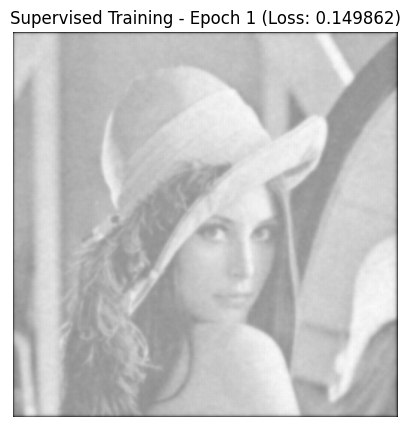

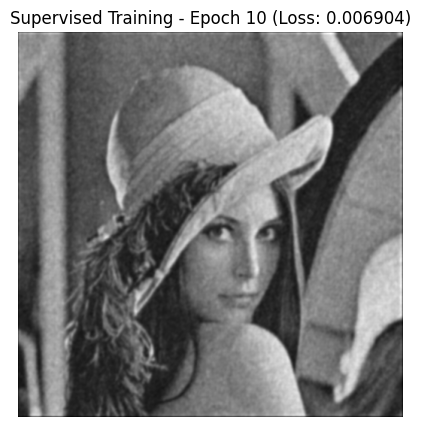

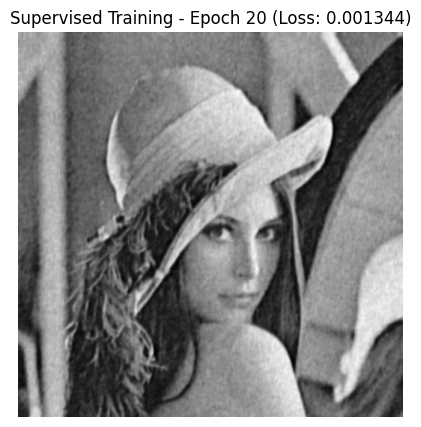

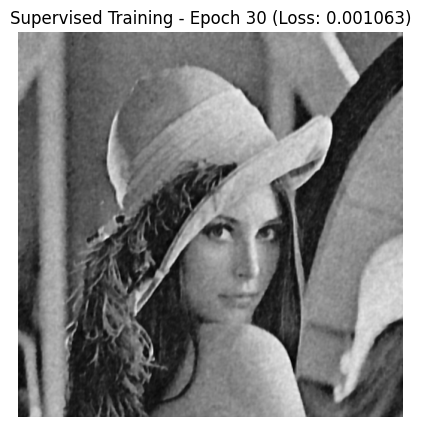

In [16]:
# Initialize model, loss criterion, and optimizer for supervised training
denoiser_supervised = Unet(in_channels=1, out_channels=1).to(device)
criterion_supervised = nn.MSELoss()
optimizer_supervised = optim.Adam(denoiser_supervised.parameters(), lr=0.001)

epochs_supervised = 30
supervised_losses = []

for epoch in range(1, epochs_supervised + 1):
    denoiser_supervised.train()
    epoch_loss = 0.0

    for batch_noisy, batch_clean in supervised_loader:
        batch_noisy = batch_noisy.to(device)
        batch_clean = batch_clean.to(device)

        optimizer_supervised.zero_grad()

        # Forward pass
        output = denoiser_supervised(batch_noisy)

        # Loss calculation comparing predictions directly against the clean targets
        loss = criterion_supervised(output, batch_clean)
        loss.backward()
        optimizer_supervised.step()

        epoch_loss += loss.item() * batch_noisy.size(0)

    epoch_loss /= len(supervised_loader.dataset)
    supervised_losses.append(epoch_loss)

    # Display reconstruction progress visually
    if epoch % 10 == 0 or epoch == 1:
        denoiser_supervised.eval()
        with torch.no_grad():
            current_output = denoiser_supervised(fixed_noisy_input).cpu()
        current_img = torch.clamp(current_output.squeeze(), 0.0, 1.0).numpy()

        fig, ax = plt.subplots(figsize=(5, 5))
        ax.imshow(current_img, cmap='gray')
        ax.set_title(f'Supervised Training - Epoch {epoch} (Loss: {epoch_loss:.6f})')
        ax.axis('off')
        plt.show()

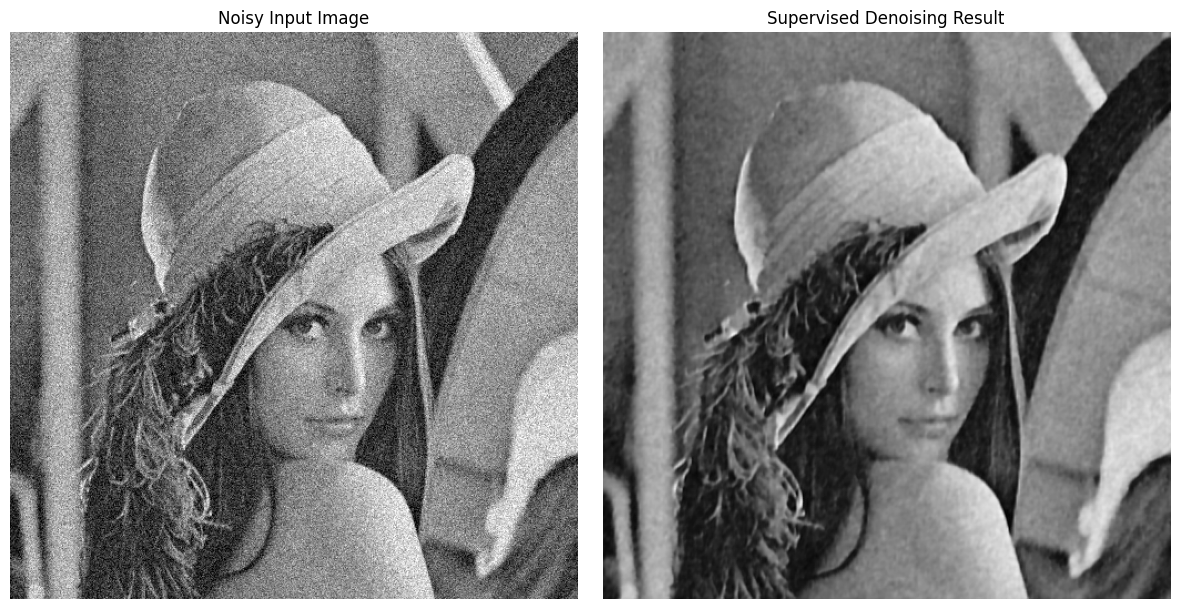

In [17]:
# Evaluate and display supervised denoising performance on the full image
denoiser_supervised.eval()
with torch.no_grad():
    output_tensor_supervised = denoiser_supervised(fixed_noisy_input).cpu()

denoised_supervised_np = torch.clamp(output_tensor_supervised.squeeze(), 0.0, 1.0).numpy()
denoised_image_scaled_supervised = (denoised_supervised_np * 255.0).astype(np.uint8)

# Save the supervised denoised image
output_path_supervised = "denoised_lena_supervised.png"
saved_image_supervised = Image.fromarray(denoised_image_scaled_supervised)
saved_image_supervised.save(output_path_supervised)

# Display comparisons
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(noisy, cmap='gray')
axes[0].set_title('Noisy Input Image')
axes[0].axis('off')

axes[1].imshow(denoised_image_scaled_supervised, cmap='gray')
axes[1].set_title('Supervised Denoising Result')
axes[1].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
fig.savefig('unet_n2c_comparison.png', bbox_inches='tight', dpi=300)